# Active subspace of the total cost of a fully renewable European power system (PyPSA-Eur)

Stored data from

F. Neumann and T. Brown, *Broad ranges of investment configurations for renewable power systems, robust to
cost uncertainty and near-optimality*, iScience 26(5):106702, 2023.
[doi:10.1016/j.isci.2023.106702](https://doi.org/10.1016/j.isci.2023.106702)

Fabian Neumann (1, 2, 3) and Tom Brown (1, 2)

1 Department of Digital Transformation in Energy Systems, Institute of Energy Technology, Technische Universität
Berlin (TUB), Einsteinufer 25 (TA 8), 10587 Berlin, Germany; 2 Institute for Automation and Applied Informatics
(IAI), Karlsruhe Institute of Technology (KIT), Hermann-von-Helmholtz-Platz 1, 76344 Eggenstein-Leopoldshafen,
Germany; 3 Lead contact.

Notebook: Claude (Anthropic) for P. Constantine, 2026

Page numbers below are the journal's printed page numbers.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 2023106702                 # the only seed: every bootstrap and Monte Carlo draw below uses it
t_start = time.perf_counter()
warnings.simplefilter('ignore', ac.ValidityWarning)   # v1 notes on estimator assumptions; discussed in the text

## Summary

Neumann and Brown solved the PyPSA-Eur capacity-expansion linear program of a fully renewable European
electricity system for 500 Halton samples of five capital-cost multipliers (onshore wind, offshore wind,
solar, hydrogen storage, battery storage) with a 37-node model, and for 15 of them with a 128-node model, and
published every run. The total annual system cost of the 500 least-cost runs has a one-dimensional active
subspace: local linear gradients give $\lambda_1/\lambda_2 = 26.32$ (95 % bootstrap 21.97–30.55), the weight
vector $w_1 = (0.841, 0.174, 0.181, 0.436, 0.199)$ is fixed to within a bootstrap subspace distance of 0.0113, and
a quadratic in $w_1^\top z$ predicts the cost with leave-one-out $R^2 = 0.9665$ (0.9868 with a second variable).
Four independent routes agree on $w_1$ to $|w^\top w_1| \ge 0.9968$: a global quadratic, gradients from the
envelope theorem of the linear program, the gradients of the authors' published polynomial-chaos surrogates, and
a linear fit to the 15 high-fidelity runs; $w_1^2$ reproduces the paper's first-order Sobol' indices of system
cost (Fig. 5A) to within 0.03.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients, $\mathbf{C}$ is estimated from values: local linear fits on nearest neighbours give
approximate gradients, and the global quadratic estimator (QPHD) fits one quadratic and averages the outer
product of its gradient. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in
Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Capacity expansion** (pp. 13–15). PyPSA-Eur chooses generator capacities $G_{i,r}$, storage power
capacities $H_{i,s}$, line capacities $F_l$ and the hourly dispatch $g_{i,r,t}$ at the nodes $i$ of a European
network for one weather year (2013) to minimize the total annual system cost (Eq. 1, p. 13)

$$\min_{G,H,F,g}\ \Big\{ \sum_{i,r} c_{i,r} G_{i,r} + \sum_{i,s} c_{i,s} H_{i,s} + \sum_l c_l F_l
+ \sum_{i,r,t} w_t\, o_{i,r}\, g_{i,r,t} \Big\},$$

with annualized capital costs $c_\ast$ and variable costs $o_{i,r}$, subject to linear constraints: capacity
potentials (Eqs. 2–4), renewable availability (Eq. 5), storage dispatch and energy balance (Eqs. 6–10), nodal
balance (Eq. 11), Kirchhoff's voltage law through a cycle basis (Eq. 12) and line limits (Eq. 13). The
minimized cost is written $C = \min_x \{c^\top x \mid Ax \le b\}$ (Eq. 14, p. 15). The system is fully
renewable (onshore and offshore wind, solar, existing hydro), with battery storage (6 h at full power) and
hydrogen storage (electrolysis, fuel cell and underground storage, 168 h) as the extendable storage (pp. 4, 16).
Two resolutions (p. 16): a **low-fidelity** model with 37 nodes, 4-hourly, and a transport model of the flows
(no Eq. 12), and a **high-fidelity** model with 128 nodes, 2-hourly, with linearized load flow. A
low-fidelity run took about 5 min and 3 GB, a high-fidelity run about 5 h and 20 GB (p. 20). The runs were
solved with Gurobi (p. 14); the paper also solves 100 near-optimal problems per sample (Eqs. 15–17), which
`all_runs.npz` contains but this notebook does not analyse.

**Inputs** (m = 5). The paper treats the cost uncertainty as uncertainty in the annuities of the five
technologies, independent and uniform between the optimistic and pessimistic DEA 2050 projections (Table 1,
p. 5; pp. 16–17). In the authors' workflow each input is a multiplier $f_i$ of a technology's capital cost,
uniform on $[\ell_i, 1]$ (file `config.yaml` of the authors' repository); $f_i = 1$ is, by inference from the
ratios below, the pessimistic annuity. The stored inputs are these multipliers.

In [2]:
# The five inputs: capital-cost multipliers f_i that scale the pessimistic DEA 2050 annuity of each
# technology (the solved model uses f_i x annuity). Bounds: config.yaml 'uncertainties' of the authors'
# workflow, U(lower, 1). Table 1 (p. 5) gives the overnight CAPEX ranges they were built from.
NAMES = ['f_onwind', 'f_offwind', 'f_solar', 'f_H2', 'f_battery']
LABELS = ['onshore wind', 'offshore wind', 'solar', 'hydrogen storage', 'battery storage']
LOWER = np.array([0.670, 0.726, 0.679, 0.429, 0.240])
UPPER = np.ones(5)
CAPEX_T1 = {'f_onwind': (800, 1190), 'f_offwind': (1420, 1950), 'f_solar': (420, 620),
            'f_H2': (668, 2002), 'f_battery': (316, 1306)}     # EUR/kW, Table 1 (p. 5)
m = len(NAMES)
print(f"{'input':10s} {'multiplier range':>17s} {'Table 1 CAPEX (EUR/kW)':>23s} {'CAPEX ratio lo/hi':>18s}")
for n, lo in zip(NAMES, LOWER):
    a, b = CAPEX_T1[n]
    print(f'{n:10s} {f"[{lo:.3f}, 1]":>17s} {f"[{a}, {b}]":>23s} {a / b:18.3f}')

input       multiplier range  Table 1 CAPEX (EUR/kW)  CAPEX ratio lo/hi
f_onwind          [0.670, 1]             [800, 1190]              0.672
f_offwind         [0.726, 1]            [1420, 1950]              0.728
f_solar           [0.679, 1]              [420, 620]              0.677
f_H2              [0.429, 1]             [668, 2002]              0.334
f_battery         [0.240, 1]             [316, 1306]              0.242


The lower bounds of the multipliers are close to the CAPEX ratios of Table 1 for four technologies but not for
hydrogen storage (0.429 against 668/2002 = 0.334). Annuities are not proportional to overnight costs when
fixed O&M and lifetimes differ, and the hydrogen entry combines three components of different lifetimes, so the
two ratios need not agree; the paper does not give the annuity range itself, so how 0.429 was obtained is not
known (DATA.md, "Unknowns", notes a possible lead in the authors' cost files). The notebook uses the multipliers as stored. **Quantity of interest:** the total annual system cost
`tsc` (bn EUR/a) of the least-cost solution. The data also hold the installed capacities (GW), the
transmission volume (TWkm) and a Gini coefficient; the capacities are summarized at the end.

## Load the data

Four files, converted losslessly from the authors' repository by `convert_data.py`: the 500 low-fidelity and
15 high-fidelity least-cost runs (CSV), all 52,015 stored runs (`all_runs.npz`), and the authors' fitted
least-cost polynomial-chaos surrogates (`pce_least_cost.csv`).

In [3]:
def read(path):
    """Values and the column names from the second '#' line of one of this data set's CSVs."""
    with open(path) as fh:
        fh.readline()
        cols = [c.split(' [')[0] for c in fh.readline()[2:].strip().split(',')]
    return np.loadtxt(path, delimiter=','), cols


LC, cols = read('least_cost_low.csv')          # 500 least-cost runs, low-fidelity model
HC, cols_h = read('least_cost_high.csv')       # 15 least-cost runs, high-fidelity model
PCE, pcols = read('pce_least_cost.csv')        # the authors' fitted least-cost PCE surrogates
assert cols == cols_h and cols[:m] == NAMES
QOIS = cols[m:]
X, Y = LC[:, :m], LC[:, m:]
XH, YH = HC[:, :m], HC[:, m:]
UNITS = {'onwind': 'GW', 'offwind': 'GW', 'wind': 'GW', 'solar': 'GW', 'H2': 'GW', 'battery': 'GW',
         'transmission': 'TWkm', 'tsc': 'bn EUR/a', 'gini': '1'}
f, fH = Y[:, QOIS.index('tsc')], YH[:, QOIS.index('tsc')]
with np.load('all_runs.npz') as z:
    obj_low, obj_labels = z['low_objective'], list(z['objective_labels'])
    print('all_runs.npz: low', z['low_inputs'].shape, z['low_outputs'].shape,
          '| high', z['high_inputs'].shape, z['high_outputs'].shape)
print('least-cost low-fidelity: X', X.shape, 'outputs', Y.shape, '| high-fidelity: X', XH.shape, 'outputs', YH.shape)
print('PCE coefficients:', PCE.shape, '| QoIs:', QOIS)
print('low-fidelity runs by objective:', {str(o): int(np.sum(obj_low == k)) for k, o in enumerate(obj_labels)})

all_runs.npz: low (50500, 5) (50500, 9) | high (1515, 5) (1515, 9)
least-cost low-fidelity: X (500, 5) outputs (500, 9) | high-fidelity: X (15, 5) outputs (15, 9)
PCE coefficients: (31, 21) | QoIs: ['onwind', 'offwind', 'wind', 'solar', 'H2', 'battery', 'transmission', 'tsc', 'gini']
low-fidelity runs by objective: {'cost': 500, 'onwind': 5000, 'offwind': 10000, 'wind': 10000, 'solar': 5000, 'H2': 10000, 'battery': 5000, 'transmission': 5000}


In [4]:
print(f"{'input':10s} {'sample min':>10s} {'sample max':>10s} {'distinct':>8s}  all on a 0.001 grid")
for i, n in enumerate(NAMES):
    on_grid = np.allclose(X[:, i] * 1000, np.round(X[:, i] * 1000), atol=1e-9)
    print(f'{n:10s} {X[:, i].min():10.3f} {X[:, i].max():10.3f} {len(np.unique(X[:, i])):8d}  {on_grid}')
print('inside [LOWER, UPPER]:', bool(np.all((X >= LOWER) & (X <= UPPER))))
idx = [int(np.flatnonzero(np.all(X == x, axis=1))[0]) for x in XH]
print('high-fidelity samples found among the low-fidelity rows at rows', idx)
space = ac.Uniform(LOWER, UPPER, names=NAMES)
Z = space.to_normalized(X)
print(f'normalized sample means {np.round(Z.mean(0), 3)}, variances {np.round(Z.var(0), 3)} (uniform: 0, 0.333)')
print(f'tsc: low-fidelity {f.min():.1f}-{f.max():.1f} bn EUR/a, high-fidelity {fH.min():.1f}-{fH.max():.1f} bn EUR/a')

input      sample min sample max distinct  all on a 0.001 grid
f_onwind        0.671      0.999      326  True
f_offwind       0.726      0.999      272  True
f_solar         0.680      0.999      312  True
f_H2            0.429      0.998      380  True
f_battery       0.241      0.995      336  True
inside [LOWER, UPPER]: True
high-fidelity samples found among the low-fidelity rows at rows [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
normalized sample means [ 0.001 -0.003 -0.003 -0.005 -0.011], variances [0.333 0.332 0.333 0.334 0.332] (uniform: 0, 0.333)
tsc: low-fidelity 164.1-217.7 bn EUR/a, high-fidelity 169.0-206.5 bn EUR/a


### Design and checks of the data

The paper draws its samples from a Halton sequence (p. 19): 500 for the low-fidelity model, of which the first
15 are run with the high-fidelity model (Eq. 29, p. 19; pp. 19–20). The cell above confirms the subset: the 15
high-fidelity samples are rows 0–14 of the low-fidelity file. The stored multipliers lie on a 0.001 grid (the
workflow rounds the Halton points to three decimals) inside the box, and their normalized means and variances
are those of a uniform design (0.001 to −0.011 and 0.332–0.334, against 0 and 0.333). The 500 points are a
deterministic low-discrepancy design, not independent draws, so the bootstrap intervals below treat them as
if they were i.i.d. and are approximate. The system cost spans 164.1–217.7 bn EUR/a (low fidelity), close to
the 160–220 bn EUR/a quoted in the paper (p. 2, Fig. 3).

**Scaling.** Each multiplier is mapped to $[-1, 1]$ through its own bounds,
$z_i = (2 f_i - \ell_i - 1)/(1 - \ell_i)$, by `ac.Uniform(LOWER, UPPER)`, i.e. through its uniform CDF; the data
are passed in physical units and v1 normalizes once.

## Estimate the active subspace

**Estimator.** The model gives no gradients. With M = 500 runs and m = 5 inputs, local linear gradients (each a
least-squares plane through a run's 8 nearest neighbours, the library default) are possible and keep the
estimate local; they are the main estimate. QPHD (one global quadratic, 21 coefficients) and OLS are computed
as checks. Both use the same 500 runs; the bootstrap (500 replicates) resamples the runs. Eigenvector signs:
the paper has no eigenvectors, so each $w_j$ is signed to correlate positively with the cost
(`ac.orient(by='covariance')`).

In [5]:
t0 = time.perf_counter()
G_ll = ac.local_linear_gradients(X=X, f=f, space=space, qoi='tsc')
sub_ll = ac.active_subspace(grads=G_ll, n=2, nboot=500, bootstrap_vectors=2, rng=SEED, qoi='tsc')
sub_ll = ac.with_dimension(ac.orient(sub_ll, by='covariance', X=X, f=f, columns=2), n=1)
sub_qp = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', n=1, nboot=500, rng=SEED, qoi='tsc')
sub_qp = ac.orient(sub_qp, by='covariance', X=X, f=f, columns=2)
sub_ols = ac.active_subspace(space=space, X=X, f=f, estimator='ols', n=1, qoi='tsc')


def ratios(lam):
    return lam[:-1] / lam[1:]


for name, s in [('local linear', sub_ll), ('QPHD', sub_qp)]:
    lam = s.eigenvalues
    ci = ac.bootstrap_interval(s.bootstrap_eigenvalues)
    print(f'{name:12s} eigenvalues {np.array2string(lam, precision=4)}')
    print(f'{"":12s} 95% bootstrap  low {np.array2string(ci[0], precision=4)}')
    print(f'{"":12s}                high {np.array2string(ci[1], precision=4)}')
    be = s.bootstrap_eigenvalues
    rci = np.percentile(be[:, 0] / be[:, 1], [2.5, 97.5])
    print(f'{"":12s} ratios lam_k/lam_k+1 {np.array2string(ratios(lam), precision=2)}; lam1/lam2 95% bootstrap '
          f'[{rci[0]:.2f}, {rci[1]:.2f}]; share of trace off w1 {1 - lam[0] / lam.sum():.4f}')
print(f'OLS: |w1 . w1_ll| = {abs(sub_ols.W[:, 0] @ sub_ll.W[:, 0]):.4f}')
print(f'QPHD: |w1 . w1_ll| = {abs(sub_qp.W[:, 0] @ sub_ll.W[:, 0]):.4f}')
print(f'({time.perf_counter() - t0:.1f} s)')

local linear eigenvalues [376.3663  14.3      9.8135   5.0939   3.8984]
             95% bootstrap  low [368.7715  12.4559   8.4208   3.2368   1.6309]
                            high [385.4215  17.0244  10.9904   8.5071   5.5705]
             ratios lam_k/lam_k+1 [26.32  1.46  1.93  1.31]; lam1/lam2 95% bootstrap [21.97, 30.55]; share of trace off w1 0.0809
QPHD         eigenvalues [3.7532e+02 1.6154e+01 1.1306e+01 7.7290e-01 1.3235e-01]
             95% bootstrap  low [3.7249e+02 1.4380e+01 9.7804e+00 5.7800e-01 6.8694e-02]
                            high [3.7901e+02 1.8233e+01 1.2556e+01 9.9125e-01 2.1318e-01]
             ratios lam_k/lam_k+1 [23.23  1.43 14.63  5.84]; lam1/lam2 95% bootstrap [20.71, 26.13]; share of trace off w1 0.0703
OLS: |w1 . w1_ll| = 0.9998
QPHD: |w1 . w1_ll| = 0.9998
(1.1 s)


The local linear estimate has one large eigenvalue, 376.3663, and four small ones (14.3 to 3.8984):
$\lambda_1/\lambda_2 = 26.32$ (95 % bootstrap 21.97–30.55), while the next ratios are 1.46, 1.93 and 1.31, so
there is no second gap. QPHD gives the same picture ($\lambda_1/\lambda_2 = 23.23$, bootstrap 20.71–26.13), and
the OLS direction agrees with the local linear $w_1$ to $|w^\top w_1| = 0.9998$. The share of the trace off
$w_1$ is 0.0809 (local linear) and 0.0703 (QPHD). The two estimators differ in the trailing eigenvalues
(5.0939 and 3.8984 against 7.7290e-01 and 1.3235e-01): local linear gradients of a function known to about 0.3 bn EUR/a
(see the envelope fit below) carry noise that fills the small eigenvalues.

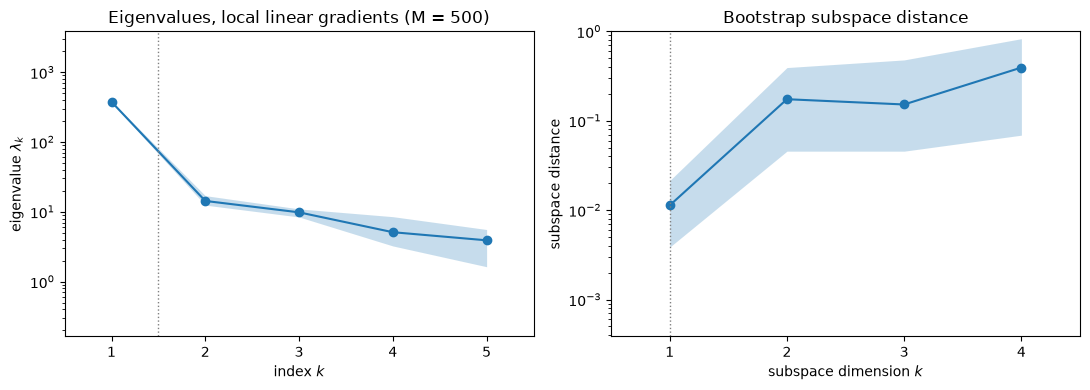

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub_ll, ax=axs[0])
axs[0].set_title('Eigenvalues, local linear gradients (M = 500)')
ac.plotting.plot_subspace_errors(sub_ll, ax=axs[1])
axs[1].set_title('Bootstrap subspace distance')
fig.tight_layout()
plt.close(fig)
fig

In [7]:
d = sub_ll.bootstrap_distances
for k in range(m - 1):
    lo_, hi_ = np.percentile(d[:, k], [2.5, 97.5])
    print(f'n = {k + 1}: bootstrap subspace distance mean {d[:, k].mean():.4f}, 95% interval [{lo_:.4f}, {hi_:.4f}]')
d = sub_qp.bootstrap_distances[:, 0]
print(f'QPHD n = 1: mean {d.mean():.4f}, 95% interval [{np.percentile(d, 2.5):.4f}, {np.percentile(d, 97.5):.4f}]')

n = 1: bootstrap subspace distance mean 0.0113, 95% interval [0.0039, 0.0214]
n = 2: bootstrap subspace distance mean 0.1741, 95% interval [0.0456, 0.3933]
n = 3: bootstrap subspace distance mean 0.1520, 95% interval [0.0456, 0.4789]
n = 4: bootstrap subspace distance mean 0.3935, 95% interval [0.0689, 0.8277]
QPHD n = 1: mean 0.0044, 95% interval [0.0017, 0.0082]


**Dimension.** The eigenvalues fall by a factor 26.32 after the first and then decline gently; the bootstrap
distance of the one-dimensional subspace is small (mean 0.0113, 95 % interval 0.0039–0.0214), while a
two-dimensional subspace is poorly determined (mean 0.1741, up to 0.3933), as expected when $\lambda_2$ and
$\lambda_3$ are close (ratio 1.46). The next cell compares surrogates on one and two active variables.

In [8]:
sub2 = ac.with_dimension(sub_ll, n=2)
print(f"{'active variables':18s} {'surrogate':22s} {'LOO R2':>7s}")
for s, k in [(sub_ll, 1), (sub2, 2)]:
    for deg in [1, 2, 3]:
        sur = ac.fit_surrogate(X=X, f=f, subspace=s, kind='poly', degree=deg)
        print(f'{k:18d} {"polynomial, degree " + str(deg):22s} {sur.loo_r_squared:7.4f}')
full = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=3)
print(f'{"all 5 inputs":18s} {"polynomial, degree 3":22s} {full.loo_r_squared:7.4f}')

active variables   surrogate               LOO R2
                 1 polynomial, degree 1    0.9666
                 1 polynomial, degree 2    0.9665
                 1 polynomial, degree 3    0.9666
                 2 polynomial, degree 1    0.9666
                 2 polynomial, degree 2    0.9868
                 2 polynomial, degree 3    0.9881
all 5 inputs       polynomial, degree 3    0.9998


A polynomial in $w_1^\top z$ predicts the cost with leave-one-out $R^2 = 0.9666$ (linear), 0.9665 (quadratic) and
0.9666 (cubic): along $w_1$ the cost is essentially linear. A second active variable raises it to 0.9868
(quadratic), and a cubic in all five inputs reaches 0.9998, so the cost is a smooth function of the inputs with
small noise, and about 3 % of its variance lies off $w_1$ (1 − 0.9666). (The LOO error refits the polynomial but not the
direction.) **The notebook uses n = 1**: the gap after $\lambda_1$ is the only one, the direction is tightly
determined, and one variable explains about 97 % of the variance; a second variable adds about 0.02 of $R^2$ but
is not separated from the third by any gap.

f_onwind   w1 +0.841 [+0.834, +0.847]  w1^2 0.707   w2 -0.392   QPHD w1 +0.846
f_offwind  w1 +0.174 [+0.160, +0.187]  w1^2 0.030   w2 +0.809   QPHD w1 +0.161
f_solar    w1 +0.181 [+0.172, +0.189]  w1^2 0.033   w2 +0.343   QPHD w1 +0.180
f_H2       w1 +0.436 [+0.426, +0.447]  w1^2 0.190   w2 +0.211   QPHD w1 +0.437
f_battery  w1 +0.199 [+0.185, +0.211]  w1^2 0.040   w2 +0.172   QPHD w1 +0.186


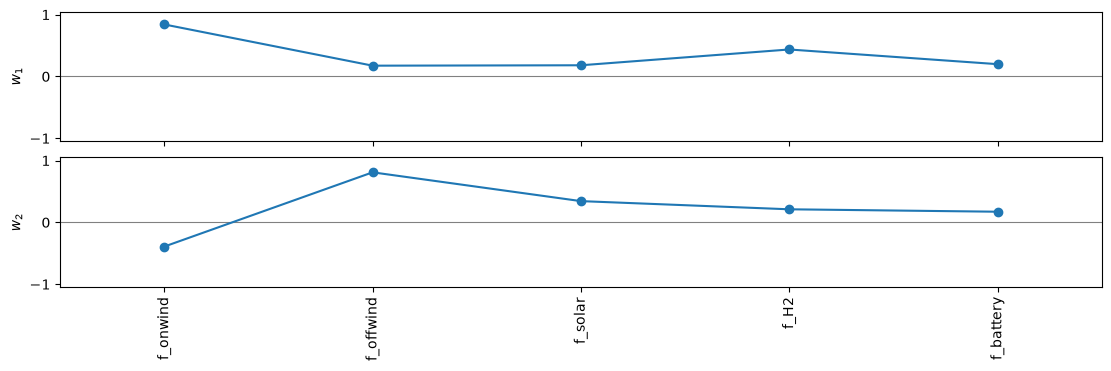

In [9]:
fig, axs = ac.plotting.plot_eigenvectors(sub_ll, indices=[0, 1], labels=NAMES, figsize=(11, 3.6))
w1, w2 = sub_ll.W[:, 0], sub_ll.W[:, 1]
bv = sub_ll.bootstrap_eigenvectors
ci1 = np.percentile(bv[:, :, 0], [2.5, 97.5], axis=0)
for i, n in enumerate(NAMES):
    print(f'{n:10s} w1 {w1[i]:+.3f} [{ci1[0, i]:+.3f}, {ci1[1, i]:+.3f}]  w1^2 {w1[i] ** 2:.3f}   '
          f'w2 {w2[i]:+.3f}   QPHD w1 {sub_qp.W[i, 0]:+.3f}')
plt.close(fig)
fig

All five weights are positive, so the cost rises with every multiplier. Onshore wind dominates
($w_1 = 0.841$, 95 % bootstrap 0.834–0.847), followed by hydrogen storage (0.436); offshore wind, solar and
battery storage have weights 0.174–0.199. Since the inputs are scaled by their ranges, a weight combines how
much is spent on a technology with how wide its cost range is (the hydrogen and battery multipliers have the
widest ranges, [0.429, 1] and [0.240, 1]). The second eigenvector, which is not used, contrasts offshore wind (+0.809)
with onshore wind (−0.392): substituting one kind of wind for the other is the main residual degree of freedom.
QPHD gives the same $w_1$ ($|w^\top w_1| = 0.9998$).

residual sd of the 1-D quadratic 2.041 bn EUR/a; tsc sd 11.219 bn EUR/a; correlation of the residual with w2^T z +0.090


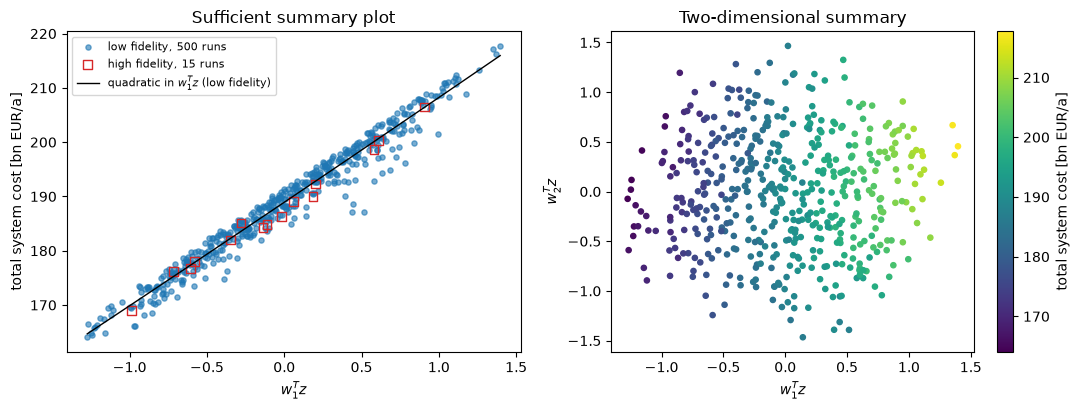

In [10]:
y_lo = Z @ w1
y_hi = space.to_normalized(XH) @ w1
sur1 = ac.fit_surrogate(X=X, f=f, subspace=sub_ll, kind='poly', degree=2)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].scatter(y_lo, f, s=14, c='tab:blue', alpha=0.6, label='low fidelity, 500 runs')
axs[0].scatter(y_hi, fH, s=40, marker='s', facecolor='none', edgecolor='tab:red',
               label='high fidelity, 15 runs')
yy = np.linspace(y_lo.min(), y_lo.max(), 100)
axs[0].plot(yy, sur1.evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in $w_1^T z$ (low fidelity)')
axs[0].set_xlabel('$w_1^T z$')
axs[0].set_ylabel('total system cost [bn EUR/a]')
axs[0].legend(fontsize=8)
axs[0].set_title('Sufficient summary plot')
sc = axs[1].scatter(Z @ w1, Z @ w2, c=f, s=14, cmap='viridis')
axs[1].set_xlabel('$w_1^T z$')
axs[1].set_ylabel('$w_2^T z$')
fig.colorbar(sc, ax=axs[1], label='total system cost [bn EUR/a]')
axs[1].set_title('Two-dimensional summary')
fig.tight_layout()
res = f - sur1.evaluate(y_lo[:, None])
print(f'residual sd of the 1-D quadratic {res.std():.3f} bn EUR/a; tsc sd {f.std():.3f} bn EUR/a; '
      f'correlation of the residual with w2^T z {np.corrcoef(res, Z @ w2)[0, 1]:+.3f}')
plt.close(fig)
fig

The 500 low-fidelity costs collapse onto a nearly straight band along $w_1^\top z$; the residual standard
deviation of the quadratic is 2.041 bn EUR/a against a cost standard deviation of 11.219 bn EUR/a. The 15
high-fidelity runs, projected on the same $w_1$, lie along the same band, mostly slightly below it (their
cost is on average 1.094 bn EUR/a lower than the low-fidelity cost at the same samples; see below). The residual correlates weakly with
$w_2^\top z$ (+0.090); the right panel shows the small second-direction variation that the two-variable
surrogate picks up.

## Checks of the direction

### Gradients from the envelope theorem

This check is this data set's inference, not part of the paper. The multiplier $f_i$ scales the capital-cost
coefficients of technology $i$ in the objective of a linear program, so by the envelope theorem the derivative
of the optimal cost is the capital cost of the optimal capacities at $f_i = 1$:
$\partial C / \partial f_i = a_i^\top x_i^\ast$ (where the optimum is unique). The node-level annuities $a_i$ are
not stored, but the cost is then $C = \sum_i f_i\, a_i^\top x_i^\ast + {}$(terms not scaled by any $f_i$), so a
linear fit of the cost on the products $f_i \cdot \mathrm{cap}_i$, the transmission volume and a constant
estimates one average annuity per GW for each technology.

In [11]:
# Envelope theorem: C(f) = min_x { sum_i f_i a_i^T x_i + (unscaled cost terms) | Ax <= b }, so
# dC/df_i = a_i^T x_i*, the annual capital cost of technology i at multiplier 1 (pessimistic annuity).
# The per-node annuities a_i are not stored. With one average annuity abar_i per GW,
#     tsc ~ sum_i f_i abar_i cap_i + b * transmission + c,
# a linear least-squares fit over the 500 runs estimates abar_i (an inference of this data set).
CAPS = ['onwind', 'offwind', 'solar', 'H2', 'battery']
cap = np.column_stack([Y[:, QOIS.index(c)] for c in CAPS])
A = np.column_stack([X * cap, Y[:, QOIS.index('transmission')], np.ones(len(X))])
coef, *_ = np.linalg.lstsq(A, f, rcond=None)
r = f - A @ coef
print('fitted annuity per GW at f = 1 [bn EUR/a per GW]:', {k: round(float(v), 4) for k, v in zip(CAPS, coef[:5])})
print(f'transmission coefficient {coef[5]:.4f} bn EUR/a per TWkm, constant {coef[6]:.2f} bn EUR/a')
print(f'fit residual sd {r.std():.3f} bn EUR/a, max |residual| {abs(r).max():.3f} bn EUR/a, R2 {1 - r.var() / f.var():.5f}')
# a check of the onshore-wind coefficient from the authors' cost file data/costs_pessimist.csv
# (1190 EUR/kW, FOM 1.18 %/a, 30 a) and the discount rate 0.07 of config.pypsaeur.yaml
rate = 0.07
ann_on = 1190 * (rate / (1 - (1 + rate) ** -30) + 0.0118) / 1e3
print(f'onshore wind annuity from the cost file: {ann_on:.4f} bn EUR/a per GW (fit {coef[0]:.4f})')
G_env = cap * coef[:5]                          # physical gradient d tsc / d f_i [bn EUR/a]
sub_env = ac.active_subspace(space=space, grads=G_env, n=1, nboot=500, rng=SEED, qoi='tsc')
sub_env = ac.orient(sub_env, by='covariance', X=X, f=f)
lam = sub_env.eigenvalues
be = sub_env.bootstrap_eigenvalues
rci = np.percentile(be[:, 0] / be[:, 1], [2.5, 97.5])
print(f'envelope-gradient eigenvalues {np.array2string(lam, precision=4)}, ratios {np.array2string(ratios(lam), precision=2)}, '
      f'lam1/lam2 95% bootstrap [{rci[0]:.2f}, {rci[1]:.2f}]')
print(f'|w1_env . w1_ll| = {abs(sub_env.W[:, 0] @ w1):.4f}; w1_env = {np.round(sub_env.W[:, 0], 3)}')
gl = space.grads_to_physical(G_ll.grads)
cosg = np.sum(gl * G_env, 1) / np.linalg.norm(gl, axis=1) / np.linalg.norm(G_env, axis=1)
print(f'cosine between local linear and envelope gradients per run: median {np.median(cosg):.3f}, '
      f'5% quantile {np.percentile(cosg, 5):.3f}')

fitted annuity per GW at f = 1 [bn EUR/a per GW]: {'onwind': 0.1138, 'offwind': 0.249, 'solar': 0.0504, 'H2': 0.2578, 'battery': 0.1396}
transmission coefficient 0.0637 bn EUR/a per TWkm, constant 15.10 bn EUR/a
fit residual sd 0.308 bn EUR/a, max |residual| 1.180 bn EUR/a, R2 0.99925
onshore wind annuity from the cost file: 0.1099 bn EUR/a per GW (fit 0.1138)


envelope-gradient eigenvalues [3.9683e+02 2.0844e+01 1.7163e+01 1.2367e+00 3.2111e-01], ratios [19.04  1.21 13.88  3.85], lam1/lam2 95% bootstrap [15.75, 22.57]
|w1_env . w1_ll| = 0.9993; w1_env = [0.841 0.169 0.168 0.426 0.232]
cosine between local linear and envelope gradients per run: median 0.995, 5% quantile 0.927


The fit is nearly exact ($R^2 = 0.99925$, residual sd 0.308 bn EUR/a, at most 1.180), which supports the
envelope structure and also sizes the noise in the stored costs (the solver runs with barrier tolerance
$10^{-3}$ and no crossover, `config.yaml`). The fitted onshore-wind annuity, 0.1138 bn EUR/a per GW, is close to
0.1099 computed from the authors' pessimistic cost file (1190 EUR/kW, fixed O&M 1.18 %/a, 30 years, discount
rate 0.07). With these gradients $\lambda_1/\lambda_2 = 19.04$ (bootstrap 15.75–22.57) and $w_1$ agrees with the
local linear one to 0.9993; per run, the local linear and envelope gradients have median cosine 0.995 (5 %
quantile 0.927). In this reading $w_1$ is the dominant direction of the vector of capital spending on the five
technologies, measured in range-scaled coordinates.

### The authors' polynomial-chaos surrogates

The paper fits sparse polynomial chaos expansions of total degree 3 by Lasso regression (penalty 0.005, Eq. 25,
p. 18) to 400 of the 500 low-fidelity runs (100 are held out, p. 20), and builds a multi-fidelity surrogate by
adding a linear correction fitted to the 15 high-fidelity runs (Eqs. 27–30, p. 19). The stored polynomials
(`pce_least_cost.csv`, monomials in the raw multipliers) are differentiated exactly and their gradients averaged
over 20,000 uniform Monte Carlo points.

In [12]:
E = PCE[:, :m].astype(int)                       # exponents of the 31 monomials
JL, JH = pcols.index('low_tsc'), pcols.index('high_tsc')


def pce_value(c, Xp):
    return np.prod(Xp[:, None, :] ** E[None], axis=2) @ c


def pce_grad(c, Xp):
    G = np.empty_like(Xp)
    for j in range(m):
        Ej = E.copy()
        Ej[:, j] = np.maximum(E[:, j] - 1, 0)
        G[:, j] = np.prod(Xp[:, None, :] ** Ej[None], axis=2) @ (c * E[:, j])
    return G


def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)


Xmc = space.sample(20000, rng=SEED)
pce_subs = {}
for lab, j in [('low-fidelity PCE', JL), ('multi-fidelity PCE', JH)]:
    c = PCE[:, j]
    s = ac.active_subspace(space=space, grads=pce_grad(c, Xmc), n=1, nboot=200, rng=SEED, qoi='tsc')
    s = ac.orient(s, by='reference', reference=w1[:, None])
    pce_subs[lab] = s
    lam = s.eigenvalues
    print(f'{lab}: R2 on the 500 low-fidelity runs {r2(f, pce_value(c, X)):.4f}, on the 15 high-fidelity '
          f'runs {r2(fH, pce_value(c, XH)):.4f}; mean(high runs - PCE) {np.mean(fH - pce_value(c, XH)):+.2e} bn EUR/a')
    be = s.bootstrap_eigenvalues
    rci = np.percentile(be[:, 0] / be[:, 1], [2.5, 97.5])
    print(f'   eigenvalues {np.array2string(lam, precision=4)}, ratios {np.array2string(ratios(lam), precision=2)}, '
          f'lam1/lam2 95% bootstrap over the Monte Carlo points [{rci[0]:.2f}, {rci[1]:.2f}]')
    print(f'   w1 {np.round(s.W[:, 0], 3)}, |w1 . w1_ll| {abs(s.W[:, 0] @ w1):.4f}')
# finite-difference check of the analytic PCE gradient at 5 points
h = 1e-6
Xc = Xmc[:5]
fd = np.column_stack([(pce_value(PCE[:, JH], Xc + h * np.eye(m)[j]) - pce_value(PCE[:, JH], Xc - h * np.eye(m)[j])) / (2 * h)
                      for j in range(m)])
print(f'PCE gradient vs central differences: max relative difference {np.max(np.abs(fd - pce_grad(PCE[:, JH], Xc))) / np.max(np.abs(fd)):.1e}')

low-fidelity PCE: R2 on the 500 low-fidelity runs 0.9872, on the 15 high-fidelity runs 0.9783; mean(high runs - PCE) -1.01e+00 bn EUR/a
   eigenvalues [3.6504e+02 6.7417e+00 1.2670e+00 1.8507e-01 1.4128e-03], ratios [ 54.15   5.32   6.85 131.  ], lam1/lam2 95% bootstrap over the Monte Carlo points [53.33, 55.09]
   w1 [0.839 0.183 0.179 0.442 0.188], |w1 . w1_ll| 0.9999


multi-fidelity PCE: R2 on the 500 low-fidelity runs 0.9763, on the 15 high-fidelity runs 0.9972; mean(high runs - PCE) +1.79e-05 bn EUR/a
   eigenvalues [3.5789e+02 6.7741e+00 1.2136e+00 2.0824e-01 2.0364e-03], ratios [ 52.83   5.58   5.83 102.26], lam1/lam2 95% bootstrap over the Monte Carlo points [52.03, 53.75]
   w1 [0.839 0.128 0.224 0.433 0.206], |w1 . w1_ll| 0.9980
PCE gradient vs central differences: max relative difference 2.1e-10


Both surrogates have the same one-dimensional structure, with a larger gap than the data ($\lambda_1/\lambda_2$
= 54.15 for the low-fidelity and 52.83 for the multi-fidelity surrogate, Monte Carlo bootstrap 53.33–55.09 and
52.03–53.75): a sparse cubic smooths away part of the variation off $w_1$ that the runs contain. Their
$w_1$ agree with the local linear $w_1$ to 0.9999 and 0.9980; the multi-fidelity surrogate puts less weight on
offshore wind (0.128 against 0.174) and more on solar (0.224 against 0.181). The low-fidelity surrogate
predicts the 500 runs with $R^2 = 0.9872$ (400 of them are its training runs) and lies 1.01 bn EUR/a above the
high-fidelity runs on average; the multi-fidelity surrogate removes that offset (mean difference of order
$10^{-5}$ bn EUR/a, $R^2 = 0.9972$ on the 15 runs it was corrected with). The analytic gradient matches central
differences to a relative error of order $10^{-10}$.

In [13]:
# Exact Sobol' indices of the stored PCEs: project each polynomial (cubic, in the raw multipliers) onto
# orthonormal Legendre polynomials of t = (2 f - lower - upper) / (upper - lower) on [-1, 1]^5 with a
# 4-point Gauss-Legendre rule per input (exact for these degrees), then sum squared coefficients.
from itertools import product
from numpy.polynomial import legendre as leg

tq, wq = leg.leggauss(4)
gidx = np.array(list(product(range(4), repeat=m)))
Tq, Wq = tq[gidx], np.prod(wq[gidx] / 2, axis=1)
Xq = space.from_normalized(Tq)
ALPHA = np.array([a for a in product(range(4), repeat=m) if sum(a) <= 3])
PSI = np.column_stack([np.prod([leg.legval(Tq[:, i], [0] * a[i] + [1]) * np.sqrt(2 * a[i] + 1)
                                for i in range(m)], axis=0) for a in ALPHA])


def sobol(c):
    coef = PSI.T @ (Wq * pce_value(c, Xq))
    nz = ALPHA.sum(1) > 0
    V = np.sum(coef[nz] ** 2)
    S1 = np.array([np.sum(coef[(ALPHA[:, i] > 0) & (ALPHA.sum(1) == ALPHA[:, i])] ** 2) for i in range(m)]) / V
    ST = np.array([np.sum(coef[ALPHA[:, i] > 0] ** 2) for i in range(m)]) / V
    return S1, ST


S1_lo, ST_lo = sobol(PCE[:, JL])
S1_mf, ST_mf = sobol(PCE[:, JH])
FIG5A = [71, 2, 4, 16, 5]                         # Fig. 5A (p. 8): first-order Sobol' indices of tsc, %
print(f"{'input':10s} {'Fig.5A S1':>9s} {'S1 MF PCE':>9s} {'ST MF PCE':>9s} {'S1 LF PCE':>9s} "
      f"{'w1^2 (LL)':>9s}   (Sobol' indices in %)")
for i, n in enumerate(NAMES):
    print(f'{n:10s} {FIG5A[i]:9d} {100 * S1_mf[i]:9.1f} {100 * ST_mf[i]:9.1f} {100 * S1_lo[i]:9.1f} '
          f'{w1[i] ** 2:9.3f}')
print(f'sum of first-order indices: MF PCE {S1_mf.sum():.3f}, LF PCE {S1_lo.sum():.3f}')
FIG5A_ALL = {'wind': [68, 19, 5, 0, 1], 'onwind': [58, 31, 1, 0, 0], 'offwind': [40, 42, 1, 1, 1],
             'solar': [20, 8, 44, 1, 13], 'transmission': [6, 1, 1, 72, 0], 'H2': [0, 3, 0, 51, 44],
             'battery': [0, 0, 1, 12, 81], 'tsc': FIG5A}
dev = {}
for q, v in FIG5A_ALL.items():
    for lab in ['low', 'high']:
        S1q, _ = sobol(PCE[:, pcols.index(f'{lab}_{q}')])
        dev[(q, lab)] = np.max(np.abs(np.round(100 * S1q) - np.array(v)))
print('largest |stored-PCE S1 - Fig. 5A| over the 5 inputs, percentage points:')
print('  multi-fidelity PCE:', {q: int(dev[(q, 'high')]) for q in FIG5A_ALL})
print('  low-fidelity PCE:  ', {q: int(dev[(q, 'low')]) for q in FIG5A_ALL})
S1t_lo, _ = sobol(PCE[:, pcols.index('low_transmission')])
S1t_mf, _ = sobol(PCE[:, pcols.index('high_transmission')])
print(f'transmission, first-order indices %: low-fidelity PCE {np.round(100 * S1t_lo, 1)}, '
      f'multi-fidelity PCE {np.round(100 * S1t_mf, 1)}, Fig. 5A {FIG5A_ALL["transmission"]}')

input      Fig.5A S1 S1 MF PCE ST MF PCE S1 LF PCE w1^2 (LL)   (Sobol' indices in %)
f_onwind          71      69.6      69.8      69.6     0.707
f_offwind          2       1.6       1.9       3.3     0.030
f_solar            4       5.0       5.0       3.2     0.033
f_H2              16      18.7      19.2      19.5     0.190
f_battery          5       4.4       4.8       3.7     0.040
sum of first-order indices: MF PCE 0.993, LF PCE 0.993
largest |stored-PCE S1 - Fig. 5A| over the 5 inputs, percentage points:
  multi-fidelity PCE: {'wind': 2, 'onwind': 1, 'offwind': 1, 'solar': 5, 'transmission': 8, 'H2': 2, 'battery': 2, 'tsc': 3}
  low-fidelity PCE:   {'wind': 3, 'onwind': 3, 'offwind': 6, 'solar': 8, 'transmission': 27, 'H2': 13, 'battery': 14, 'tsc': 4}
transmission, first-order indices %: low-fidelity PCE [ 1.2 28.1 12.  50.7  0.9], multi-fidelity PCE [ 5.4  9.2  0.2 75.   3. ], Fig. 5A [6, 1, 1, 72, 0]


The stored multi-fidelity surrogate reproduces Fig. 5A for the system cost to within 3 percentage points
(69.6, 1.6, 5.0, 18.7, 4.4 % against 71, 2, 4, 16, 5 %), and its first-order indices sum to 0.993. The paper
notes "noticeable higher-order effects, which are most extensive for transmission", but that "the first-order
effects dominate" (p. 5); for the system cost the stored surrogate agrees. Across all eight outputs of Fig. 5A the multi-fidelity
surrogate is within 1–8 points and the low-fidelity surrogate within 3–27 points, consistent with the figure having been
made from the multi-fidelity surrogate. The remaining differences are larger than rounding; the workflow splits training
and test runs with a random shuffle and no stored seed (`config.yaml`, `scripts/surrogate.py`), so the stored
polynomials may come from a different fit than the one in the figure (not known). For a function that is nearly
linear along one direction, the first-order Sobol' index of input $i$ is close to $w_{1,i}^2$; here $w_1^2$ =
0.707, 0.030, 0.033, 0.190, 0.040 against the paper's 0.71, 0.02, 0.04, 0.16, 0.05.

### The 15 high-fidelity runs

The paper's results combine both models; the high-fidelity runs alone are too few for local gradients or a
quadratic (21 coefficients), so the only data-based direction is the OLS one.

In [14]:
# The 15 high-fidelity runs: too few for gradients or a quadratic (21 coefficients), so OLS only
ZH = space.to_normalized(XH)
fL15 = f[idx]                                     # low-fidelity runs at the same 15 cost samples
sub_h = ac.active_subspace(space=space, X=XH, f=fH, estimator='ols', n=1, nboot=500, rng=SEED, qoi='tsc_high')
sub_l15 = ac.active_subspace(space=space, X=XH, f=fL15, estimator='ols', n=1, qoi='tsc_low15')
A1 = np.column_stack([np.ones(15), ZH])
for lab, y in [('high fidelity', fH), ('low fidelity, same 15 samples', fL15), ('difference high - low', fH - fL15)]:
    beta, *_ = np.linalg.lstsq(A1, y, rcond=None)
    rr = y - A1 @ beta
    print(f'{lab:30s} mean {y.mean():8.3f}  sd {y.std():6.3f}  linear-fit R2 {1 - rr.var() / y.var():.4f}  '
          f'slopes {np.round(beta[1:], 3)}')
dh = sub_h.bootstrap_distances[:, 0]
print(f'OLS direction, high fidelity: {np.round(sub_h.W[:, 0], 3)}; bootstrap distance mean {dh.mean():.3f}, '
      f'95% interval [{np.percentile(dh, 2.5):.3f}, {np.percentile(dh, 97.5):.3f}]')
print(f'|w_high . w1_ll| = {abs(sub_h.W[:, 0] @ w1):.4f}, |w_high . w_low(15)| = {abs(sub_h.W[:, 0] @ sub_l15.W[:, 0]):.4f}, '
      f'|w_low(15) . w1_ll| = {abs(sub_l15.W[:, 0] @ w1):.4f}')
print(f'correlation of the high-fidelity tsc with w1^T z (low-fidelity w1): {np.corrcoef(fH, ZH @ w1)[0, 1]:.4f}')

high fidelity                  mean  186.603  sd  9.664  linear-fit R2 0.9953  slopes [15.562  2.992  4.847  8.361  3.585]
low fidelity, same 15 samples  mean  187.697  sd 10.192  linear-fit R2 0.9900  slopes [16.23   4.052  4.605  9.239  2.84 ]
difference high - low          mean   -1.094  sd  1.053  linear-fit R2 0.8457  slopes [-0.668 -1.059  0.242 -0.878  0.745]
OLS direction, high fidelity: [0.823 0.158 0.256 0.442 0.19 ]; bootstrap distance mean 0.057, 95% interval [0.015, 0.141]
|w_high . w1_ll| = 0.9968, |w_high . w_low(15)| = 0.9973, |w_low(15) . w1_ll| = 0.9960
correlation of the high-fidelity tsc with w1^T z (low-fidelity w1): 0.9931


A linear function of the five multipliers explains the high-fidelity cost with in-sample $R^2 = 0.9953$
(15 runs, 6 coefficients), and its direction agrees with the low-fidelity $w_1$ to 0.9968 (bootstrap distance
mean 0.057, 95 % interval 0.015–0.141). The high-fidelity cost is on average 1.094 bn EUR/a below the
low-fidelity cost at the same samples (sd 1.053); a linear fit explains 0.8457 of the variance of this
difference, which is the linear correction the paper uses (p. 19). **For the system cost, the low-fidelity runs,
the multi-fidelity surrogate and the high-fidelity runs give the same active direction.**

## The installed capacities

The same estimator for the other outputs of the 500 low-fidelity least-cost runs (local linear gradients, no
bootstrap), with LOO $R^2$ of a quadratic surrogate on 1, 2 and 3 active variables and the agreement of $w_1$ with
QPHD. These capacities come from the low-fidelity model only; the paper's Fig. 5 uses the multi-fidelity
surrogate, and for transmission the two models differ (in the stored surrogates the offshore-wind index of
transmission is 28 % in the low-fidelity and 9 % in the multi-fidelity fit).

In [15]:
print(f"{'QoI':12s} {'units':5s} {'l1/l2':>6s} {'l2/l3':>6s} {'LOO R2 n=1':>10s} {'n=2':>6s} {'n=3':>6s}  "
      f"w1 (onwind, offwind, solar, H2, battery)   |w1 . w1_QPHD|")
OTHER = {}
for q in ['onwind', 'offwind', 'wind', 'solar', 'H2', 'battery', 'transmission']:
    y = Y[:, QOIS.index(q)]
    g = ac.local_linear_gradients(X=X, f=y, space=space, qoi=q)
    s = ac.active_subspace(grads=g, n=1, qoi=q)
    s = ac.orient(s, by='covariance', X=X, f=y, columns=m)
    sq = ac.active_subspace(space=space, X=X, f=y, estimator='qphd', n=1, qoi=q)
    loo = [ac.fit_surrogate(X=X, f=y, subspace=ac.with_dimension(s, n=k), kind='poly', degree=2).loo_r_squared
           for k in (1, 2, 3)]
    lam = s.eigenvalues
    OTHER[q] = (s, loo)
    print(f'{q:12s} {UNITS[q]:5s} {lam[0] / lam[1]:6.2f} {lam[1] / lam[2]:6.2f} {loo[0]:10.3f} {loo[1]:6.3f} {loo[2]:6.3f}  '
          f'{np.array2string(s.W[:, 0], precision=2, sign="+"):40s} {abs(sq.W[:, 0] @ s.W[:, 0]):.3f}')

QoI          units  l1/l2  l2/l3 LOO R2 n=1    n=2    n=3  w1 (onwind, offwind, solar, H2, battery)   |w1 . w1_QPHD|
onwind       GW      5.63   2.17      0.971  0.971  0.971  [-0.8  +0.59 +0.08 -0.01 +0.02]          0.999
offwind      GW      4.31   2.23      0.971  0.971  0.972  [+0.74 -0.67 +0.05 +0.05 +0.01]          0.999


wind         GW      7.25   1.89      0.962  0.962  0.963  [-0.84 +0.5  +0.2  +0.04 +0.05]          1.000
solar        GW      7.09   1.62      0.932  0.937  0.963  [+0.52 +0.07 -0.8  +0.08 -0.3 ]          0.996
H2           GW      7.45   1.77      0.949  0.977  0.977  [+0.01 +0.1  +0.   -0.77 +0.63]          0.999


battery      GW      5.93   1.18      0.906  0.909  0.938  [+0.04 -0.02 -0.08 +0.43 -0.9 ]          0.999
transmission TWkm    2.10   1.58      0.805  0.811  0.841  [-0.19 +0.6  +0.34 +0.7  -0.06]          0.996


No capacity has a gap like the system cost: $\lambda_1/\lambda_2$ is 4.31–7.45 for the six capacities and 2.10
for transmission. Each capacity still depends mainly on one direction (one-variable LOO $R^2$ 0.906–0.971), which
contrasts a technology's own cost with that of its substitute: onshore against offshore wind for the wind
capacities, solar against onshore wind and battery for solar, and hydrogen against battery storage for the two
storage capacities, as in the paper's Fig. 5A (p. 8). Transmission is the least one-dimensional (LOO $R^2$ 0.805
with one variable); in the low-fidelity runs it depends on the hydrogen-storage (+0.7) and offshore-wind (+0.6)
multipliers.

## Comparison with the paper

The paper reports no active subspace; the table compares the quantities it does report.

| quantity | paper (page) | this notebook |
|---|---|---|
| number of runs | 500 low-fidelity and 15 high-fidelity samples, 101 problems each; 50,500 + 1,515 runs (p. 20) | 50,500 + 1,515 runs; 500 + 15 least-cost |
| design | Halton sequence; high-fidelity samples a subset (pp. 19–20) | high-fidelity samples are low-fidelity rows 0–14 |
| total system cost range | 160–220 bn EUR/a (p. 2, Fig. 3) | 164.1–217.7 (low-fidelity runs), 169.0–206.5 (high-fidelity runs) |
| first-order Sobol' indices of total system cost, % (onwind, offwind, solar, H2, battery) | 71, 2, 4, 16, 5 (Fig. 5A, p. 8) | 69.6, 1.6, 5.0, 18.7, 4.4 (stored multi-fidelity PCE, exact); $w_1^2$ = 0.707, 0.030, 0.033, 0.190, 0.040 |
| interactions | "Although there are noticeable higher-order effects, which are most extensive for transmission, the first-order effects dominate" (p. 5) | first-order indices of the stored PCE sum to 0.993 |
| surrogate accuracy for system cost | high $R^2$; prediction of system cost "remarkably accurate" (Fig. 2, p. 4; p. 20) | stored low-fidelity PCE $R^2$ = 0.9872 on the 500 runs; 1-D quadratic LOO $R^2$ = 0.9665 |
| active subspace, eigenvalue ratio | not reported | $\lambda_1/\lambda_2$ = 26.32 (local linear), 23.23 (QPHD), 19.04 (envelope), 52.83 (multi-fidelity PCE) |
| leading direction $w_1$ | not reported | (0.841, 0.174, 0.181, 0.436, 0.199) |

## References

- F. Neumann and T. Brown, Broad ranges of investment configurations for renewable power systems, robust to cost
  uncertainty and near-optimality, *iScience* 26(5):106702, 2023.
  [doi:10.1016/j.isci.2023.106702](https://doi.org/10.1016/j.isci.2023.106702)
- F. Neumann and T. Brown, broad-ranges (code and results), https://github.com/fneum/broad-ranges, commit
  b95bbc98 (files used unchanged since tag v0.1.0); archived at Zenodo,
  [doi:10.5281/zenodo.6641551](https://doi.org/10.5281/zenodo.6641551) (cited in the paper) and
  [doi:10.5281/zenodo.6642651](https://doi.org/10.5281/zenodo.6642651) (cited by the repository).
- J. Hörsch, F. Hofmann, D. Schlachtberger and T. Brown, PyPSA-Eur: an open optimisation model of the European
  transmission system, *Energy Strategy Reviews* 22:207–215, 2018.
  [doi:10.1016/j.esr.2018.08.012](https://doi.org/10.1016/j.esr.2018.08.012)
- T. Brown, J. Hörsch and D. Schlachtberger, PyPSA: Python for Power System Analysis, *Journal of Open Research
  Software* 6(1):4, 2018. [doi:10.5334/jors.188](https://doi.org/10.5334/jors.188)
- B. Sudret, Global sensitivity analysis using polynomial chaos expansions, *Reliability Engineering & System
  Safety* 93(7):964–979, 2008. [doi:10.1016/j.ress.2007.04.002](https://doi.org/10.1016/j.ress.2007.04.002)
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

## Acknowledgments

The paper's authors acknowledge funding from the Helmholtz Association under grant no. VH-NG-1352 (p. 11).

In [16]:
print(f'notebook run time {time.perf_counter() - t_start:.1f} s')

notebook run time 7.5 s
